# Twitter Sentiment Analysis System - End-to-End MLOps Pipeline

**Dataset:** Sentiment140 (downloaded to `data/` on first run; 1.6M tweets labelled negative / positive)
**Model:** TF-IDF + Logistic Regression  **Serving:** Flask API in Docker  **MLOps:** GitHub Actions, Docker Hub, Kubernetes



| # | Section | Project requirement |
|---|---|---|
| 0 | Configuration | - |
| 1 | Environment setup | Install Python libraries, Docker; check tools |
| 2 | GitHub repository | Version control for CI/CD |
| 3 | Data collection | Download/load Sentiment140 tweets and explore them |
| 4 | Preprocessing | Remove URLs / mentions / special characters, lowercase, tokenize |
| 5 | Train / validation / test split | Separate validation dataset |
| 6 | Model training & validation | Logistic regression, accuracy + F1 |
| 7 | Model versioning | Versioned model registry |
| 8 | Flask API | Receive a tweet, return its sentiment |
| 9 | Automated tests | API receives requests and returns the right sentiment |
| 10 | Docker | Dockerfile, build, run, push to Docker Hub |
| 11 | CI/CD | GitHub Actions: test -> build -> push -> deploy |
| 12 | Model versioning & rollback | Documented rollback paths |
| 13 | Kubernetes deployment | Deployment, Service, autoscaling |
| 14 | Summary | - |



## 0. Configuration

In [1]:
import os
import shutil
import tempfile
import urllib.request
import zipfile
from pathlib import Path

PROJECT_DIR = Path.cwd()                                   # folder that holds this notebook
DATA_DIR = PROJECT_DIR / "data"
SENTIMENT140_FILE = "training.1600000.processed.noemoticon.csv"
SENTIMENT140_URL = "https://cs.stanford.edu/people/alecmgo/trainingandtestdata.zip"
DATA_PATH = Path(os.environ.get("DATA_PATH", DATA_DIR / SENTIMENT140_FILE))

# Use the full dataset (None) or a random sample for a quicker run, e.g. 200_000
SAMPLE_SIZE = int(os.environ["SAMPLE_SIZE"]) if os.environ.get("SAMPLE_SIZE") else None
RANDOM_STATE = 42

GITHUB_REPO_URL = "https://github.com/christones/-Sentiment-analysis-system-from-Twitter-data.git"
DOCKERHUB_USERNAME = "christones"            # <-- change to your Docker Hub username
IMAGE_NAME = "sentiment-api"

# Steps that touch external tools - switch on when you are ready
RUN_GIT = False       # git init / commit / push
RUN_DOCKER = False    # docker build / run / push   (Docker Desktop must be running)
RUN_K8S = False       # kubectl apply                 (Docker Desktop Kubernetes or minikube)
INSTALL_BERT_LIBS = False  # also install torch + transformers (large download, optional)

os.chdir(PROJECT_DIR)
if not DATA_PATH.exists():
    if os.environ.get("DATA_PATH"):
        raise FileNotFoundError(f"DATA_PATH does not exist: {DATA_PATH}")
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    print("Sentiment140 dataset not found; downloading the official training archive...")
    with tempfile.TemporaryDirectory(dir=DATA_DIR) as temp_dir:
        temp_dir = Path(temp_dir)
        archive_path = temp_dir / "trainingandtestdata.zip"
        urllib.request.urlretrieve(SENTIMENT140_URL, archive_path)
        with zipfile.ZipFile(archive_path) as archive:
            member = next((name for name in archive.namelist()
                           if Path(name).name == SENTIMENT140_FILE), None)
            if member is None:
                raise FileNotFoundError(f"{SENTIMENT140_FILE} was not found in the downloaded archive")
            extracted_path = temp_dir / SENTIMENT140_FILE
            with archive.open(member) as source, extracted_path.open("wb") as target:
                shutil.copyfileobj(source, target)
            extracted_path.replace(DATA_PATH)

print("Project folder:", PROJECT_DIR)
print("Dataset:", DATA_PATH, "| exists:", DATA_PATH.exists())

Sentiment140 dataset not found; downloading the official training archive...


Project folder: E:\Willis\Predictive Analysis\FinalProject
Dataset: E:\Willis\Predictive Analysis\FinalProject\data\training.1600000.processed.noemoticon.csv | exists: True


In [2]:
import subprocess, shlex, sys

def run(cmd, check=False):
    """Run a shell command from the notebook and show its output (works on Windows and Linux)."""
    print(f"$ {cmd}")
    res = subprocess.run(cmd, shell=True, capture_output=True, text=True,
                         encoding="utf-8", errors="replace")
    out = (res.stdout or "") + (res.stderr or "")
    print(out.strip() or "(no output)")
    if check and res.returncode != 0:
        raise RuntimeError(f"Command failed with exit code {res.returncode}: {cmd}")
    return res.returncode == 0

## 1. Environment setup

**Installed on my  machine:**

* **Python 3.10 - 3.13** - https://www.python.org/downloads/
* **Docker Desktop** - https://www.docker.com/products/docker-desktop/ (enable *Settings -> Kubernetes* for Section 13)
* **Git** - https://git-scm.com/downloads
* **kubectl** - ships with Docker Desktop; or install minikube

Below we write the project folders and dependency files, then install the Python libraries:
pandas, numpy, scikit-learn, Flask, gunicorn, pytest, plotting libraries, and optionally PyTorch + Hugging Face
Transformers for BERT experiments.

In [3]:
for d in ["sentiment", "app", "tests", "models", "k8s", ".github/workflows", "reports"]:
    Path(d).mkdir(parents=True, exist_ok=True)
print("Folders ready")

Folders ready


In [4]:
%%writefile requirements.txt
# Runtime dependencies for the Flask API (installed in the Docker image)
flask>=3.0,<4
gunicorn>=22.0
scikit-learn==1.7.2
numpy>=1.26,<3
pandas>=2.1,<3
joblib>=1.3

Overwriting requirements.txt


In [5]:
%%writefile requirements-dev.txt
# Notebook + testing dependencies (on top of requirements.txt)
-r requirements.txt
jupyter
matplotlib
seaborn
requests
pytest>=8.0
flake8

Overwriting requirements-dev.txt


In [6]:
%%writefile requirements-bert.txt
# Optional: deep-learning stack for experimenting with BERT (not needed by the API)
torch
transformers

Overwriting requirements-bert.txt


In [7]:
%pip install -q -r requirements-dev.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: c:\Users\Dell\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [8]:
if INSTALL_BERT_LIBS:
    run(f'"{sys.executable}" -m pip install -q -r requirements-bert.txt')
else:
    print("Skipping torch/transformers (set INSTALL_BERT_LIBS = True to install them)")

Skipping torch/transformers (set INSTALL_BERT_LIBS = True to install them)


In [9]:
import platform, shutil, importlib

print("Python", platform.python_version(), "|", platform.system(), platform.release())
for lib in ["pandas", "numpy", "sklearn", "flask", "joblib", "matplotlib", "seaborn", "pytest",
            "torch", "transformers", "tensorflow"]:
    try:
        m = importlib.import_module(lib)
        print(f"  {lib:<13} {getattr(m, '__version__', 'installed')}")
    except ImportError:
        print(f"  {lib:<13} not installed")

print()
for tool in ["git", "docker", "kubectl", "minikube"]:
    print(f"  {tool:<9} {'found: ' + shutil.which(tool) if shutil.which(tool) else 'NOT found'}")

Python 3.14.0 | Windows 11


  pandas        2.3.3
  numpy         2.5.3


  sklearn       1.7.2


C:\Users\Dell\AppData\Local\Temp\ipykernel_15700\2365072340.py:8: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Flask 3.2. Use feature detection or 'importlib.metadata.version("flask")' instead.
  print(f"  {lib:<13} {getattr(m, '__version__', 'installed')}")


  flask         3.1.3
  joblib        1.6.0


  matplotlib    3.11.2


  seaborn       0.13.2


  pytest        9.1.1
  torch         not installed
  transformers  not installed
  tensorflow    not installed

  git       found: C:\Program Files\Git\cmd\git.EXE
  docker    found: C:\Users\Dell\AppData\Local\Programs\DockerDesktop\resources\bin\docker.EXE
  kubectl   found: C:\Users\Dell\AppData\Local\Programs\DockerDesktop\resources\bin\kubectl.EXE
  minikube  NOT found


In [10]:
# The model is saved with this scikit-learn version - the Docker image must use the same one.
import sklearn, re
pinned = re.search(r"scikit-learn==([\d.]+)", Path("requirements.txt").read_text()).group(1)
if sklearn.__version__ != pinned:
    print(f"WARNING: scikit-learn {sklearn.__version__} is installed but requirements.txt pins {pinned}.\n"
          f"Restart the kernel after the %pip cell above, or the saved model may not load in Docker.")
else:
    print("scikit-learn version matches requirements.txt:", pinned)

scikit-learn version matches requirements.txt: 1.7.2


## 2. GitHub repository (version control)

The repository is https://github.com/christones/-Sentiment-analysis-system-from-Twitter-data.
This folder becomes the local clone. The large Sentiment140 download in `data/` is **excluded** by `.gitignore` (GitHub rejects files
over 100 MB); the trained model in `models/` **is** committed so CI and Docker can use it.

The first push happens in Section 11, once there is code and a model to push.


In [11]:
%%writefile .gitignore
# Data (too big for GitHub - downloaded by the notebook and excluded from Git)
*.csv
*.zip
data/

# Python
__pycache__/
*.pyc
.venv/
venv/
.pytest_cache/
.ipynb_checkpoints/

# Local secrets
.env
kubeconfig*

Overwriting .gitignore


In [12]:
if RUN_GIT:
    if not Path(".git").exists():
        run("git init")
        run("git branch -M main")
    remotes = subprocess.run("git remote", shell=True, capture_output=True, text=True).stdout.split()
    if "origin" not in remotes:
        run(f"git remote add origin {GITHUB_REPO_URL}")
    run("git remote -v")
    run("git status --short")
else:
    print("RUN_GIT is False - skipping. Commands that would run:")
    print(f"  git init\n  git branch -M main\n  git remote add origin {GITHUB_REPO_URL}")

RUN_GIT is False - skipping. Commands that would run:
  git init
  git branch -M main
  git remote add origin https://github.com/christones/-Sentiment-analysis-system-from-Twitter-data.git


## 3. Data collection

Sentiment140 comes from http://help.sentiment140.com/for-students (the `trainingandtestdata.zip` link at the bottom of
the page). On first run, the configuration cell downloads the official archive and extracts the training file to
`data/training.1600000.processed.noemoticon.csv`. The download is skipped when the file already exists; set `DATA_PATH`
to use a different local Sentiment140-format CSV. The training file has **no header** and six columns:

| column | meaning |
|---|---|
| target | polarity: 0 = negative, 4 = positive (2 = neutral, only in the test file) |
| ids | tweet id |
| date | tweet date |
| flag | query (`NO_QUERY`) |
| user | user name |
| text | tweet text |

The loader below detects the encoding, delimiter and whether there is a header row, so it also works if the file was
re-saved with column names. Labels are mapped to **0 = negative, 1 = positive**. It rejects unexpected labels or
non-text feature data instead of quietly treating them as tweets.

In [13]:
import csv, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

S140_COLUMNS = ["target", "ids", "date", "flag", "user", "text"]
TEXT_NAMES = ["text", "tweet", "tweet_text", "sentimenttext", "content", "message"]
LABEL_NAMES = ["target", "label", "sentiment", "polarity", "class", "y"]


def sniff_encoding(path):
    with open(path, "rb") as f:
        head = f.read(1_000_000)
    if head.startswith(b"\xef\xbb\xbf"):
        return "utf-8-sig"
    if head[:2] in (b"\xff\xfe", b"\xfe\xff"):
        return "utf-16"
    try:
        head.decode("utf-8")
        return "utf-8"
    except UnicodeDecodeError as e:
        return "utf-8" if e.start > len(head) - 4 else "latin-1"


def load_tweets(path, sample_size=None, random_state=42):
    enc = sniff_encoding(path)
    with open(path, encoding=enc, errors="replace") as f:
        first_lines = "".join(f.readline() for _ in range(5))
    try:
        sep = csv.Sniffer().sniff(first_lines, delimiters=",\t;|").delimiter
    except csv.Error:
        sep = ","
    first = pd.read_csv(path, sep=sep, header=None, nrows=1, encoding=enc, encoding_errors="replace")
    first_row = [str(v).strip().lower() for v in first.iloc[0]]
    has_header = any(v in TEXT_NAMES + LABEL_NAMES for v in first_row)

    read_kw = dict(sep=sep, encoding=enc, encoding_errors="replace", on_bad_lines="skip",
                   dtype=str, keep_default_na=False)
    if has_header:
        df = pd.read_csv(path, **read_kw)
    elif len(first_row) == 6:
        df = pd.read_csv(path, header=None, names=S140_COLUMNS, **read_kw)
    else:
        df = pd.read_csv(path, header=None, **read_kw)
        df.columns = [f"col{i}" for i in range(df.shape[1])]

    lower = {c.lower().strip(): c for c in df.columns}
    text_col = next((lower[n] for n in TEXT_NAMES if n in lower), None) or \
        df.apply(lambda s: s.str.len().mean()).idxmax()
    label_col = next((lower[n] for n in LABEL_NAMES if n in lower), None) or \
        next(c for c in df.columns if c != text_col and df[c].head(10_000).nunique() <= 3)

    raw = df[label_col].str.strip().str.lower()
    mapping = {"0": 0, "4": 1, "1": 1, "-1": 0, "2": None,
               "negative": 0, "neg": 0, "positive": 1, "pos": 1}
    values = set(raw.unique())
    supported_labels = {"-1", "0", "1", "2", "4", "negative", "neg", "positive", "pos"}
    unsupported_labels = values - supported_labels
    if unsupported_labels:
        raise ValueError(f"Unexpected labels in {path}: {sorted(unsupported_labels)[:10]}. "
                         "Expected Sentiment140 polarity labels (0/4) or binary sentiment labels.")
    if values <= {"-1", "0", "1"} and "-1" in values:     # -1/0/1 scheme: 0 is neutral
        mapping["0"] = None
    if values <= {"0", "1"}:
        mapping["4"] = None
    y = raw.map(mapping)

    out = pd.DataFrame({"text": df[text_col], "label": y})
    dropped = out["label"].isna().sum()
    out = out.dropna(subset=["label"]).astype({"label": int}).reset_index(drop=True)
    if set(out["label"].unique()) != {0, 1}:
        raise ValueError(f"{path} must contain both negative and positive tweet labels; "
                         f"found {sorted(out['label'].unique())}.")
    text_sample = out["text"].sample(n=min(200, len(out)), random_state=random_state).astype(str)
    natural_language_share = text_sample.str.contains(r"[A-Za-z]{2,}", regex=True).mean()
    if natural_language_share < 0.5:
        raise ValueError(f"{path} does not look like tweet text. Set DATA_PATH to the Sentiment140 CSV.")

    print(f"encoding={enc!r} sep={sep!r} header={has_header} text column={text_col!r} "
          f"label column={label_col!r} raw labels={sorted(values)[:10]}")
    if dropped:
        print(f"Dropped {dropped:,} rows with neutral/unknown labels")
    if sample_size and sample_size < len(out):
        out = out.sample(n=sample_size, random_state=random_state).reset_index(drop=True)
        print(f"Using a random sample of {sample_size:,} tweets")
    return out, df


t0 = time.time()
df, raw_df = load_tweets(DATA_PATH, SAMPLE_SIZE, RANDOM_STATE)
print(f"Loaded {len(df):,} labelled tweets in {time.time() - t0:.1f}s")
raw_df.head()

encoding='utf-8' sep=',' header=False text column='text' label column='target' raw labels=['0', '4']
Loaded 1,600,000 labelled tweets in 5.8s


,target,ids,date,flag,user,text
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer. You shoulda got David Carr of Third Day to do it. ;D"
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by texting it... and might cry as a result School today also. Blah!
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Managed to save 50% The rest go out of bounds
3,0,1467811184,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,ElleCTF,my whole body feels itchy and like its on fire
4,0,1467811193,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,Karoli,"@nationwideclass no, it's not behaving at all. i'm mad. why am i here? because I can't see you all over there."


In [14]:
del raw_df   # free memory - we only need text + label from here on
print(df.info())
df.sample(8, random_state=RANDOM_STATE)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1600000 entries, 0 to 1599999
Data columns (total 2 columns):
 #   Column  Non-Null Count    Dtype 
---  ------  --------------    ----- 
 0   text    1600000 non-null  object
 1   label   1600000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 24.4+ MB
None


,text,label
541200,@chrishasboobs AHHH I HOPE YOUR OK!!!,0
750,"@misstoriblack cool , i have no tweet apps for my razr 2",0
766711,@TiannaChaos i know just family drama. its lame.hey next time u hang out with kim n u guys like have a sleepover or...,0
285055,School email won't open and I have geography stuff on there to revise! *Stupid School* :'(,0
705995,upper airways problem,0
379611,Going to miss Pastor's sermon on Faith...,0
1189018,on lunch....dj should come eat with me,1
667030,@piginthepoke oh why are you feeling like that?,0


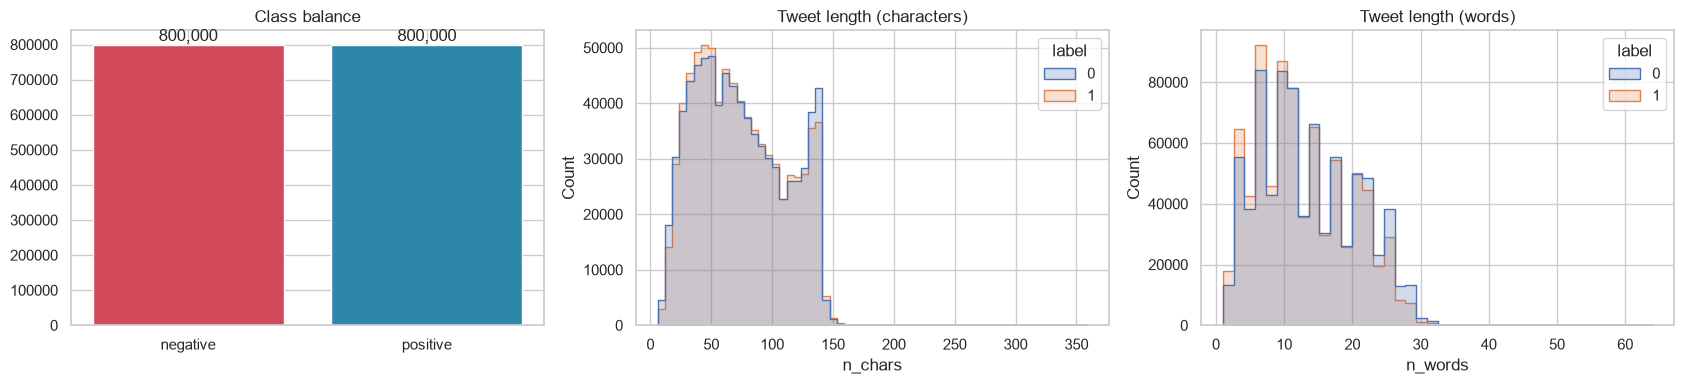

Share of tweets containing: URLs 4.8%, mentions 46.2%, hashtags 2.2%


In [15]:
df["n_chars"] = df["text"].str.len()
df["n_words"] = df["text"].str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
counts = df["label"].map({0: "negative", 1: "positive"}).value_counts()
axes[0].bar(counts.index, counts.values, color=["#d1495b", "#2e86ab"])
axes[0].set_title("Class balance")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")
sns.histplot(data=df, x="n_chars", hue="label", bins=60, ax=axes[1], element="step")
axes[1].set_title("Tweet length (characters)")
sns.histplot(data=df, x="n_words", hue="label", bins=40, ax=axes[2], element="step")
axes[2].set_title("Tweet length (words)")
plt.tight_layout(); plt.show()

share = {name: df["text"].str.contains(pattern, regex=True).mean()
         for name, pattern in [("URLs", r"https?://|www\."), ("mentions", r"@\w+"), ("hashtags", r"#\w+")]}
print("Share of tweets containing:", ", ".join(f"{k} {v:.1%}" for k, v in share.items()))

## 4. Data preprocessing

Cleaning steps (in `sentiment/preprocess.py`, shared by training **and** the API so both see identical text):

1. Decode HTML entities (`&amp;` -> `&`, `&quot;` -> `"`)
2. **Remove URLs** (`http://...`, `www...`)
3. **Remove @mentions**
4. Keep hashtag words but drop the `#`
5. **Lowercase**
6. Drop apostrophes so negations survive (`don't` -> `dont`)
7. Shorten letters repeated 3+ times (`soooo` -> `soo`)
8. **Remove special characters** (anything not a-z, 0-9 or space) and extra whitespace
9. **Tokenize** into word tokens

Stop words are deliberately **kept**: words like *not*, *no* and *but* carry sentiment.

In [16]:
%%writefile sentiment/__init__.py
from .preprocess import TextCleaner, clean_text, preprocess_tweet, tokenize  # noqa: F401
from .model_store import load_model, save_model_version, read_registry  # noqa: F401

Overwriting sentiment/__init__.py


In [17]:
%%writefile sentiment/preprocess.py
"""Tweet cleaning and tokenization shared by the notebook, the model and the API.

Keeping this in one module guarantees that the text the API receives is
processed exactly the same way as the text the model was trained on.
"""
import html
import re

from sklearn.base import BaseEstimator, TransformerMixin

URL_RE = re.compile(r"(https?://\S+|www\.\S+)", re.IGNORECASE)
MENTION_RE = re.compile(r"@\w+")
HASHTAG_RE = re.compile(r"#(\w+)")
REPEAT_RE = re.compile(r"(\w)\1{2,}")          # "soooo" -> "soo"
NON_ALNUM_RE = re.compile(r"[^a-z0-9\s]")      # special characters
SPACES_RE = re.compile(r"\s+")
TOKEN_RE = re.compile(r"[a-z0-9]+")


def clean_text(text):
    """Remove URLs, mentions and special characters, then lowercase."""
    if not isinstance(text, str):
        text = "" if text is None else str(text)
    text = html.unescape(text)                 # &amp; -> &, &quot; -> "
    text = URL_RE.sub(" ", text)
    text = MENTION_RE.sub(" ", text)
    text = HASHTAG_RE.sub(r"\1", text)         # keep the hashtag word
    text = text.lower()
    text = text.replace("'", "")               # don't -> dont (keeps negation)
    text = REPEAT_RE.sub(r"\1\1", text)
    text = NON_ALNUM_RE.sub(" ", text)
    return SPACES_RE.sub(" ", text).strip()


def tokenize(text):
    """Split already-cleaned text into lowercase word tokens."""
    return TOKEN_RE.findall(text.lower())


def preprocess_tweet(text):
    """clean_text + tokenize in one call."""
    return tokenize(clean_text(text))


class TextCleaner(BaseEstimator, TransformerMixin):
    """Stateless sklearn step so the saved Pipeline cleans raw tweets itself."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return [clean_text(t) for t in X]

    def __sklearn_is_fitted__(self):
        return True

Overwriting sentiment/preprocess.py


In [18]:
%%writefile sentiment/model_store.py
"""Tiny file-based model registry.

Layout:
    models/
      registry.json          {"current": "v2", "versions": {"v1": {...}, "v2": {...}}}
      v1/model.joblib
      v1/metadata.json
      v2/...

The version that gets served is chosen in this order:
    1. the `version` argument
    2. the MODEL_VERSION environment variable (used for rollbacks in Docker/K8s)
    3. "current" in registry.json
"""
import json
import os
import re
from datetime import datetime, timezone
from pathlib import Path

import joblib

DEFAULT_MODELS_DIR = Path(os.environ.get(
    "MODELS_DIR", Path(__file__).resolve().parent.parent / "models"))


def _registry_path(models_dir):
    return Path(models_dir) / "registry.json"


def read_registry(models_dir=DEFAULT_MODELS_DIR):
    path = _registry_path(models_dir)
    if not path.exists():
        return {"current": None, "versions": {}}
    return json.loads(path.read_text(encoding="utf-8"))


def _write_registry(registry, models_dir):
    path = _registry_path(models_dir)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(registry, indent=2), encoding="utf-8")


def _next_version(registry):
    nums = [int(m.group(1)) for v in registry["versions"]
            if (m := re.fullmatch(r"v(\d+)", v))]
    return f"v{max(nums, default=0) + 1}"


def save_model_version(pipeline, metrics, params=None, notes="",
                       models_dir=DEFAULT_MODELS_DIR, set_current=True):
    """Save a fitted pipeline as the next version (v1, v2, ...) and register it."""
    models_dir = Path(models_dir)
    registry = read_registry(models_dir)
    version = _next_version(registry)
    vdir = models_dir / version
    vdir.mkdir(parents=True, exist_ok=True)

    joblib.dump(pipeline, vdir / "model.joblib", compress=3)
    metadata = {
        "version": version,
        "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "metrics": metrics,
        "params": params or {},
        "notes": notes,
        "size_mb": round((vdir / "model.joblib").stat().st_size / 1e6, 2),
    }
    (vdir / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

    registry["versions"][version] = {
        k: metadata[k] for k in ("created_utc", "metrics", "notes")}
    if set_current or registry["current"] is None:
        registry["current"] = version
    _write_registry(registry, models_dir)
    return version


def set_current_version(version, models_dir=DEFAULT_MODELS_DIR):
    """Point the registry at another saved version (a rollback without rebuilding)."""
    registry = read_registry(models_dir)
    if version not in registry["versions"]:
        raise ValueError(f"Unknown model version {version!r}; "
                         f"available: {sorted(registry['versions'])}")
    registry["current"] = version
    _write_registry(registry, models_dir)


def resolve_version(version=None, models_dir=DEFAULT_MODELS_DIR):
    version = version or os.environ.get("MODEL_VERSION") or read_registry(models_dir)["current"]
    if not version:
        raise FileNotFoundError(
            f"No trained model found in {models_dir}. Run the notebook's training section first.")
    return version


def load_model(version=None, models_dir=DEFAULT_MODELS_DIR):
    """Return (pipeline, metadata) for the requested / configured version."""
    version = resolve_version(version, models_dir)
    vdir = Path(models_dir) / version
    if not (vdir / "model.joblib").exists():
        raise FileNotFoundError(f"Model file missing: {vdir / 'model.joblib'}")
    pipeline = joblib.load(vdir / "model.joblib")
    meta_path = vdir / "metadata.json"
    metadata = json.loads(meta_path.read_text(encoding="utf-8")) if meta_path.exists() else {}
    metadata.setdefault("version", version)
    return pipeline, metadata

Overwriting sentiment/model_store.py


In [19]:
import importlib, sys
sys.path.insert(0, str(PROJECT_DIR))
import sentiment, sentiment.preprocess, sentiment.model_store
importlib.reload(sentiment.preprocess); importlib.reload(sentiment.model_store); importlib.reload(sentiment)
from sentiment import clean_text, tokenize, preprocess_tweet, TextCleaner, save_model_version, load_model, read_registry

examples = [
    "@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer.  You shoulda got David Carr of Third Day to do it. ;D",
    "is upset that he can't update his Facebook by texting it... and might cry as a result  School today also. Blah!",
    "I LOVE this new album!!! Sooooo good #music www.example.com &amp; more",
    "@Kenichan I dived many times for the ball. Managed to save 50%  The rest go out of bounds",
]
pd.DataFrame({"original": examples,
              "cleaned": [clean_text(t) for t in examples],
              "tokens": [preprocess_tweet(t) for t in examples]})

,original,cleaned,tokens
0,"@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer. You shoulda got David Carr of Third Day to do it. ;D",aww thats a bummer you shoulda got david carr of third day to do it d,"[aww, thats, a, bummer, you, shoulda, got, david, carr, of, third, day, to, do, it, d]"
1,is upset that he can't update his Facebook by texting it... and might cry as a result School today also. Blah!,is upset that he cant update his facebook by texting it and might cry as a result school today also blah,"[is, upset, that, he, cant, update, his, facebook, by, texting, it, and, might, cry, as, a, result, school, today, a..."
2,I LOVE this new album!!! Sooooo good #music www.example.com &amp; more,i love this new album soo good music more,"[i, love, this, new, album, soo, good, music, more]"
3,@Kenichan I dived many times for the ball. Managed to save 50% The rest go out of bounds,i dived many times for the ball managed to save 50 the rest go out of bounds,"[i, dived, many, times, for, the, ball, managed, to, save, 50, the, rest, go, out, of, bounds]"


In [20]:
t0 = time.time()
df["clean_text"] = df["text"].map(clean_text)
df["n_tokens"] = df["clean_text"].map(lambda t: len(tokenize(t)))   # token lists for 1.6M tweets would use GBs of RAM
print(f"Cleaned + tokenized {len(df):,} tweets in {time.time() - t0:.1f}s "
      f"(avg {df['n_tokens'].mean():.1f} tokens per tweet)")

before = len(df)
df = df[df["clean_text"].str.len() > 0]
print(f"Removed {before - len(df):,} tweets that were empty after cleaning")
before = len(df)
df = df.drop_duplicates(subset=["clean_text", "label"])
print(f"Removed {before - len(df):,} duplicate tweets")
conflicting = df.duplicated(subset=["clean_text"], keep=False).sum()
print(f"{conflicting:,} cleaned texts appear with both labels (left in - this is label noise in Sentiment140)")
df = df.reset_index(drop=True)
print("Final dataset:", f"{len(df):,} tweets")
df[["text", "clean_text", "label"]].head(10).assign(tokens=lambda d: d["clean_text"].map(tokenize))

Cleaned + tokenized 1,600,000 tweets in 41.4s (avg 12.6 tokens per tweet)


Removed 3,630 tweets that were empty after cleaning


Removed 74,733 duplicate tweets


8,314 cleaned texts appear with both labels (left in - this is label noise in Sentiment140)


Final dataset: 1,521,637 tweets


,text,clean_text,label,tokens
0,"@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer. You shoulda got David Carr of Third Day to do it. ;D",aww thats a bummer you shoulda got david carr of third day to do it d,0,"[aww, thats, a, bummer, you, shoulda, got, david, carr, of, third, day, to, do, it, d]"
1,is upset that he can't update his Facebook by texting it... and might cry as a result School today also. Blah!,is upset that he cant update his facebook by texting it and might cry as a result school today also blah,0,"[is, upset, that, he, cant, update, his, facebook, by, texting, it, and, might, cry, as, a, result, school, today, a..."
2,@Kenichan I dived many times for the ball. Managed to save 50% The rest go out of bounds,i dived many times for the ball managed to save 50 the rest go out of bounds,0,"[i, dived, many, times, for, the, ball, managed, to, save, 50, the, rest, go, out, of, bounds]"
3,my whole body feels itchy and like its on fire,my whole body feels itchy and like its on fire,0,"[my, whole, body, feels, itchy, and, like, its, on, fire]"
4,"@nationwideclass no, it's not behaving at all. i'm mad. why am i here? because I can't see you all over there.",no its not behaving at all im mad why am i here because i cant see you all over there,0,"[no, its, not, behaving, at, all, im, mad, why, am, i, here, because, i, cant, see, you, all, over, there]"
5,@Kwesidei not the whole crew,not the whole crew,0,"[not, the, whole, crew]"
6,Need a hug,need a hug,0,"[need, a, hug]"
7,"@LOLTrish hey long time no see! Yes.. Rains a bit ,only a bit LOL , I'm fine thanks , how's you ?",hey long time no see yes rains a bit only a bit lol im fine thanks hows you,0,"[hey, long, time, no, see, yes, rains, a, bit, only, a, bit, lol, im, fine, thanks, hows, you]"
8,@Tatiana_K nope they didn't have it,nope they didnt have it,0,"[nope, they, didnt, have, it]"
9,@twittera que me muera ?,que me muera,0,"[que, me, muera]"


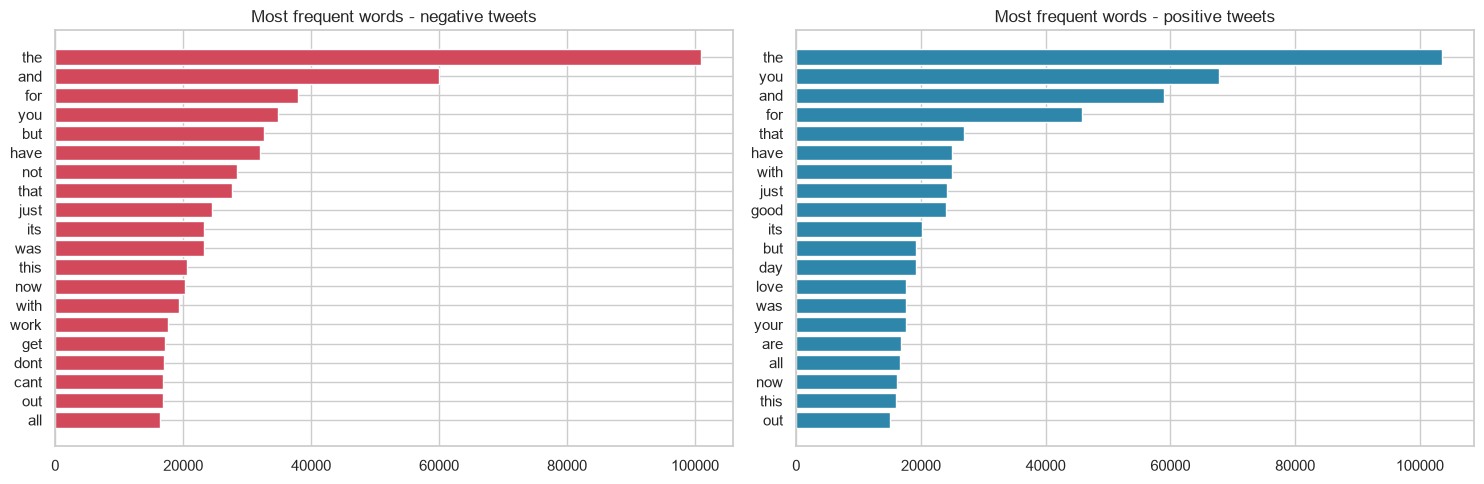

In [21]:
from collections import Counter

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (lab, name, colour) in zip(axes, [(0, "negative", "#d1495b"), (1, "positive", "#2e86ab")]):
    counter = Counter(tok for text in df.loc[df["label"] == lab, "clean_text"].head(300_000)
                      for tok in tokenize(text) if len(tok) > 2)
    words, freqs = zip(*counter.most_common(20))
    ax.barh(words[::-1], freqs[::-1], color=colour)
    ax.set_title(f"Most frequent words - {name} tweets")
plt.tight_layout(); plt.show()

## 5. Train / validation / test split

* **Train (80%)** - fit the vectorizer and the model
* **Validation (10%)** - a *separate* set used to compare hyper-parameters and pick the model
* **Test (10%)** - touched once, at the end, for an unbiased final score

All splits are stratified so each has the same class balance.

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    df["clean_text"], df["label"], test_size=0.20, stratify=df["label"], random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)
raw_test = df.loc[X_test.index, "text"]          # original tweets, used to test the saved pipeline end-to-end

split_summary = pd.DataFrame({
    "tweets": [len(X_train), len(X_val), len(X_test)],
    "positive share": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["train", "validation", "test"])
split_summary.style.format({"tweets": "{:,}", "positive share": "{:.3f}"})

,tweets,positive share
train,"1,217,309",0.497
validation,"152,164",0.497
test,"152,164",0.497


## 6. Model training and validation - Logistic Regression

**Features:** TF-IDF on word unigrams + bigrams (bigrams capture phrases like *not good*), sublinear term frequency,
words must appear in at least 5 tweets, capped at 300k features.

**Model:** logistic regression. We try several regularisation strengths `C` and choose the one with the best
**F1-score on the validation set**, reporting accuracy, precision, recall, F1 and ROC-AUC.

In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer

TFIDF_PARAMS = dict(tokenizer=tokenize, token_pattern=None, lowercase=False,
                    ngram_range=(1, 2), min_df=5, max_df=0.95, max_features=300_000,
                    sublinear_tf=True, dtype=np.float32)

t0 = time.time()
vectorizer = TfidfVectorizer(**TFIDF_PARAMS)
Xtr = vectorizer.fit_transform(X_train)
Xva = vectorizer.transform(X_val)
Xte = vectorizer.transform(X_test)
vectorizer.stop_words_ = None   # drop the list of pruned terms - it is huge and not needed for prediction
print(f"TF-IDF fitted in {time.time() - t0:.1f}s | vocabulary: {len(vectorizer.vocabulary_):,} terms")
print("Train matrix:", Xtr.shape, "| Validation:", Xva.shape, "| Test:", Xte.shape)

TF-IDF fitted in 123.4s | vocabulary: 300,000 terms
Train matrix: (1217309, 300000) | Validation: (152164, 300000) | Test: (152164, 300000)


In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)


def evaluate(model, X, y):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {"accuracy": accuracy_score(y, pred), "f1": f1_score(y, pred),
            "precision": precision_score(y, pred), "recall": recall_score(y, pred),
            "roc_auc": roc_auc_score(y, proba)}


results, models = [], {}
for C in [0.1, 0.5, 1.0, 2.0]:
    t0 = time.time()
    clf = LogisticRegression(C=C, solver="liblinear", max_iter=1000, random_state=RANDOM_STATE)
    clf.fit(Xtr, y_train)
    models[C] = clf
    row = {"C": C, **{f"train_{k}": v for k, v in evaluate(clf, Xtr, y_train).items() if k in ("accuracy", "f1")},
           **{f"val_{k}": v for k, v in evaluate(clf, Xva, y_val).items()}, "fit_seconds": time.time() - t0}
    results.append(row)
    print(f"C={C:<4} val accuracy={row['val_accuracy']:.4f}  val F1={row['val_f1']:.4f}  ({row['fit_seconds']:.0f}s)")

results_df = pd.DataFrame(results).set_index("C")
best_C = results_df["val_f1"].idxmax()
best_model = models[best_C]
print(f"\nBest C on the validation set: {best_C}")
results_df.style.format("{:.4f}").highlight_max(subset=["val_accuracy", "val_f1"], color="#c7e9c0")

C=0.1  val accuracy=0.8042  val F1=0.8049  (49s)


C=0.5  val accuracy=0.8177  val F1=0.8183  (46s)


C=1.0  val accuracy=0.8201  val F1=0.8206  (33s)


C=2.0  val accuracy=0.8211  val F1=0.8215  (40s)

Best C on the validation set: 2.0


,train_accuracy,train_f1,val_accuracy,val_f1,val_precision,val_recall,val_roc_auc,fit_seconds
C,,,,,,,,
0.100000,0.8130,0.8136,0.8042,0.8049,0.7967,0.8132,0.8837,49.2181
0.500000,0.8383,0.8386,0.8177,0.8183,0.8105,0.8262,0.8968,46.3375
1.000000,0.8499,0.8500,0.8201,0.8206,0.8130,0.8283,0.8993,32.6927
2.000000,0.8620,0.8619,0.8211,0.8215,0.8143,0.8288,0.8997,39.6462


,accuracy,f1,precision,recall,roc_auc
validation,0.8211,0.8215,0.8143,0.8288,0.8997
test (held out),0.8229,0.8234,0.8154,0.8317,0.9009


              precision    recall  f1-score   support

    negative     0.8305    0.8141    0.8223     76582
    positive     0.8154    0.8317    0.8234     75582

    accuracy                         0.8229    152164
   macro avg     0.8230    0.8229    0.8229    152164
weighted avg     0.8230    0.8229    0.8228    152164



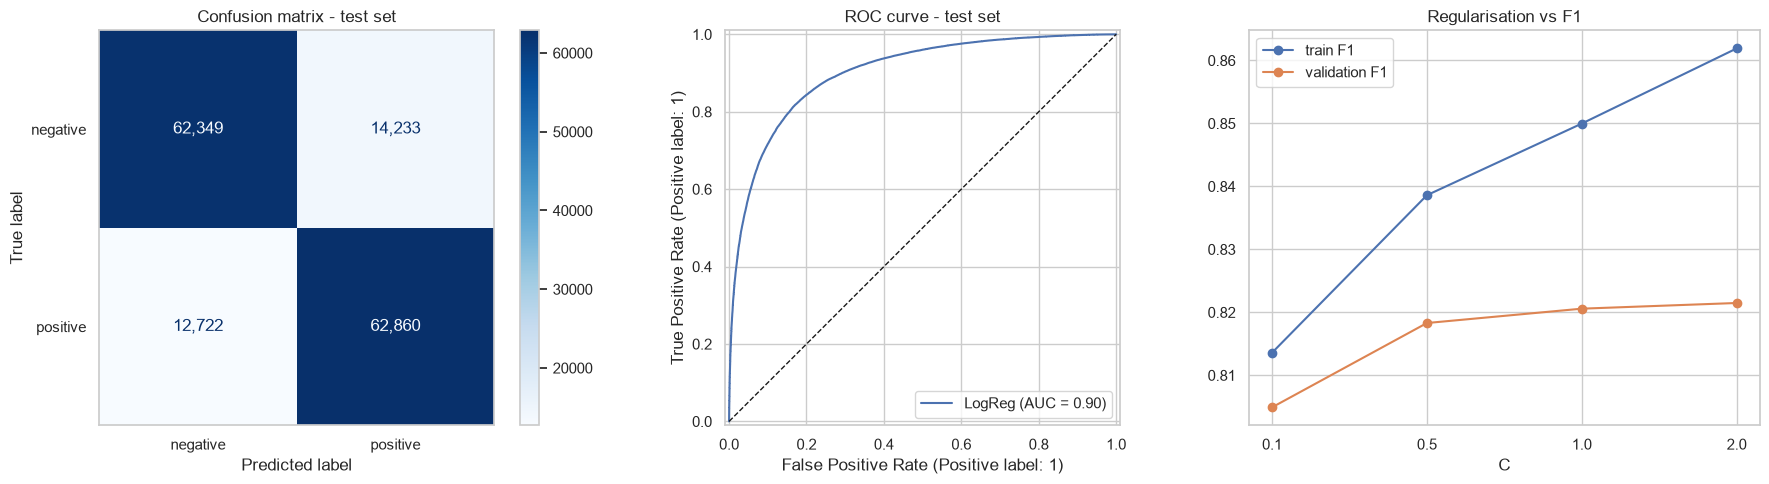

In [25]:
val_metrics = evaluate(best_model, Xva, y_val)
test_metrics = evaluate(best_model, Xte, y_test)
metrics_table = pd.DataFrame({"validation": val_metrics, "test (held out)": test_metrics}).T
display(metrics_table.style.format("{:.4f}"))

y_test_pred = best_model.predict(Xte)
print(classification_report(y_test, y_test_pred, target_names=["negative", "positive"], digits=4))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_test_pred), display_labels=["negative", "positive"]).plot(
    ax=axes[0], cmap="Blues", values_format=",")
axes[0].set_title("Confusion matrix - test set"); axes[0].grid(False)
RocCurveDisplay.from_predictions(y_test, best_model.predict_proba(Xte)[:, 1], ax=axes[1], name="LogReg")
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_title("ROC curve - test set")
axes[2].plot(results_df.index.astype(str), results_df["train_f1"], "o-", label="train F1")
axes[2].plot(results_df.index.astype(str), results_df["val_f1"], "o-", label="validation F1")
axes[2].set_xlabel("C"); axes[2].set_title("Regularisation vs F1"); axes[2].legend()
plt.tight_layout()
plt.savefig("reports/evaluation.png", dpi=120, bbox_inches="tight")
plt.show()

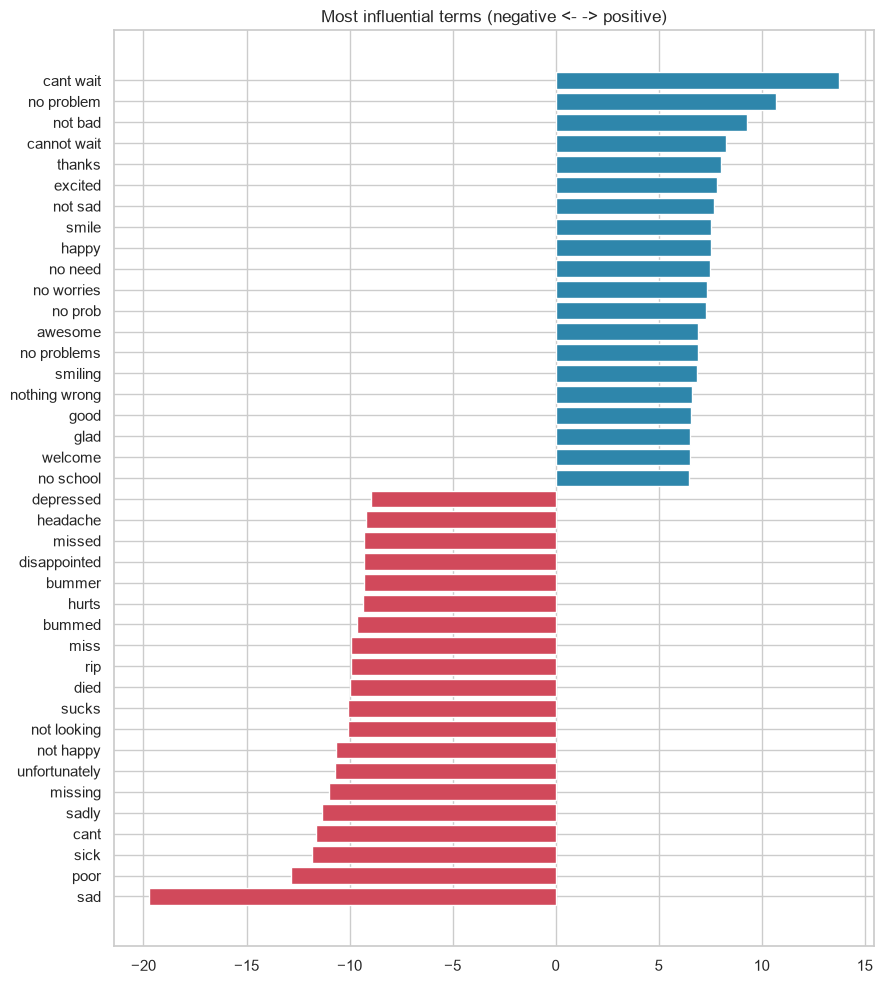

In [26]:
# Which words push predictions most strongly towards each class?
feature_names = np.array(vectorizer.get_feature_names_out())
coefs = best_model.coef_[0]
top = 20
order = np.argsort(coefs)
top_words = pd.concat([
    pd.DataFrame({"term": feature_names[order[:top]], "weight": coefs[order[:top]]}),
    pd.DataFrame({"term": feature_names[order[-top:]], "weight": coefs[order[-top:]]})])
plt.figure(figsize=(9, 10))
plt.barh(top_words["term"], top_words["weight"],
         color=np.where(top_words["weight"] > 0, "#2e86ab", "#d1495b"))
plt.title("Most influential terms (negative <- -> positive)")
plt.tight_layout(); plt.show()

In [27]:
# Error analysis: confident mistakes on the test set
test_view = pd.DataFrame({"tweet": raw_test.values, "true": y_test.values,
                          "p_positive": best_model.predict_proba(Xte)[:, 1]})
test_view["pred"] = (test_view["p_positive"] >= 0.5).astype(int)
wrong = test_view[test_view["true"] != test_view["pred"]]
wrong.assign(confidence=(wrong["p_positive"] - 0.5).abs()).sort_values("confidence", ascending=False).head(10)

,tweet,true,p_positive,pred,confidence
76167,@vivipfeif coucou miss,1,0.000109,0,0.499891
84077,@ainz0417 I'm sorry you are feeling sad and sick. I hope you feel better soon.,1,0.000180,0,0.499820
151593,@wendilynnmakeup &quot;Hurts&quot;?,1,0.000192,0,0.499808
130227,@SweetFacePoca happy,0,0.999762,1,0.499762
6435,@macnery cold! unfair,1,0.000833,0,0.499167
77448,its almost supper here im not hungery not feeling well girr i hate being sick,1,0.000986,0,0.499014
95538,@djskee not there but wish I were,1,0.001305,0,0.498695
60967,"Oh no, missed a CC tweet Work sucks!!!",1,0.001498,0,0.498502
136766,complacent smile self-satisfied!!,0,0.998361,1,0.498361
63160,@stephenaevans I want to wake up not get a migraine,1,0.001718,0,0.498282


In [28]:
# Optional: the official Sentiment140 test file (positive/negative rows only) if it is in the folder
official = PROJECT_DIR / "testdata.manual.2009.06.14.csv"
if official.exists():
    ot, _ = load_tweets(official)
    m = evaluate(best_model, vectorizer.transform(ot["text"].map(clean_text)), ot["label"])
    print("Official Sentiment140 test set:", {k: round(v, 4) for k, v in m.items()})
else:
    print("Official test file not found - skipping (optional).")

Official test file not found - skipping (optional).


## 7. Save the model as a new version

The saved artifact is a single scikit-learn `Pipeline` - **raw tweet in, sentiment out**:
`TextCleaner` -> `TfidfVectorizer` -> `LogisticRegression`.
That means the API cannot accidentally preprocess text differently from training.

`save_model_version` writes `models/vN/model.joblib` + `metadata.json` and updates `models/registry.json`.
Each run of this notebook creates the next version (v1, v2, ...).

In [29]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline([("clean", TextCleaner()), ("tfidf", vectorizer), ("clf", best_model)])

# Sanity check: the pipeline on RAW tweets must reproduce the test score
pipe_pred = pipeline.predict(raw_test.tolist())
assert (pipe_pred == y_test_pred).all(), "Pipeline output differs from the evaluated model!"
print("Pipeline reproduces test predictions on raw tweets:", f"accuracy={accuracy_score(y_test, pipe_pred):.4f}")

version = save_model_version(
    pipeline,
    metrics={"validation": {k: round(v, 4) for k, v in val_metrics.items()},
             "test": {k: round(v, 4) for k, v in test_metrics.items()}},
    params={"C": float(best_C), "solver": "liblinear",
            "tfidf": {k: v for k, v in TFIDF_PARAMS.items() if k not in ("tokenizer", "dtype")},
            "train_size": int(len(X_train)), "val_size": int(len(X_val)), "test_size": int(len(X_test)),
            "sklearn_version": sklearn.__version__, "data_file": DATA_PATH.name, "sample_size": SAMPLE_SIZE},
    notes="TF-IDF (1-2 grams) + logistic regression on Sentiment140",
)
print("Saved model version:", version)

Pipeline reproduces test predictions on raw tweets: accuracy=0.8229


Saved model version: v1


In [30]:
print(json.dumps(read_registry(), indent=2))
for p in sorted(Path("models").rglob("*")):
    if p.is_file():
        print(f"{str(p):<35} {p.stat().st_size / 1e6:8.2f} MB")

{
  "current": "v1",
  "versions": {
    "v1": {
      "created_utc": "2026-10-12T08:51:20+00:00",
      "metrics": {
        "validation": {
          "accuracy": 0.8211,
          "f1": 0.8215,
          "precision": 0.8143,
          "recall": 0.8288,
          "roc_auc": 0.8997
        },
        "test": {
          "accuracy": 0.8229,
          "f1": 0.8234,
          "precision": 0.8154,
          "recall": 0.8317,
          "roc_auc": 0.9009
        }
      },
      "notes": "TF-IDF (1-2 grams) + logistic regression on Sentiment140"
    }
  }
}
models\registry.json                    0.00 MB
models\v1\metadata.json                 0.00 MB
models\v1\model.joblib                  5.86 MB


In [31]:
# Reload from disk exactly like the API will, and classify a few new tweets
loaded, meta = load_model()
demo = ["I love this weather, what a beautiful day!",
        "Ugh, my flight got cancelled again. Worst airline ever.",
        "@support thanks for the quick fix, you guys rock http://t.co/abc",
        "not happy with the service today",
        "Just finished my exam, feeling great :)"]
p = loaded.predict_proba(demo)[:, 1]
pd.DataFrame({"tweet": demo, "sentiment": np.where(p >= 0.5, "positive", "negative"),
              "p_positive": p.round(3), "model": meta["version"]})

,tweet,sentiment,p_positive,model
0,"I love this weather, what a beautiful day!",positive,0.953,v1
1,"Ugh, my flight got cancelled again. Worst airline ever.",negative,0.001,v1
2,"@support thanks for the quick fix, you guys rock http://t.co/abc",positive,0.921,v1
3,not happy with the service today,negative,0.052,v1
4,"Just finished my exam, feeling great :)",positive,0.843,v1


## 8. Flask API

`app/app.py` loads the served model version once at start-up and exposes:

| Method | Path | Body | Response |
|---|---|---|---|
| GET | `/health` | - | `{"status": "ok", "model_version": "v1"}` |
| GET | `/model-info` | - | metadata + metrics of the served model |
| POST | `/predict` | `{"tweet": "..."}` | `sentiment`, `label`, `confidence`, `cleaned`, `model_version` |
| POST | `/predict/batch` | `{"tweets": [...]}` | one result per tweet (max 1000) |

Bad input (missing field, empty or non-string tweet, over 1000 characters) returns **HTTP 400** with an error
message. In Docker the app runs under **gunicorn** (`app/wsgi.py`); `python app/app.py` starts a dev server.

In [32]:
%%writefile app/__init__.py
# Flask API package

Overwriting app/__init__.py


In [33]:
%%writefile app/app.py
"""Flask API that classifies the sentiment of a tweet.

Endpoints
    GET  /health         liveness/readiness probe
    GET  /model-info     which model version is being served, with its metrics
    POST /predict        {"tweet": "I love this!"}
    POST /predict/batch  {"tweets": ["...", "..."]}
"""
import logging
import os
import sys
from pathlib import Path

from flask import Flask, jsonify, request

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))
from sentiment import clean_text, load_model  # noqa: E402

LABELS = {0: "negative", 1: "positive"}
MAX_BATCH = 1000
MAX_CHARS = 1000

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
log = logging.getLogger("sentiment-api")


def create_app(model_version=None, models_dir=None):
    app = Flask(__name__)
    kwargs = {"version": model_version}
    if models_dir:
        kwargs["models_dir"] = models_dir
    model, metadata = load_model(**kwargs)
    version = metadata.get("version")
    log.info("Loaded sentiment model %s", version)

    def classify(tweets):
        probs = model.predict_proba(tweets)[:, 1]
        results = []
        for tweet, p in zip(tweets, probs):
            label = int(p >= 0.5)
            results.append({
                "tweet": tweet,
                "cleaned": clean_text(tweet),
                "sentiment": LABELS[label],
                "label": label,
                "confidence": round(float(p if label else 1 - p), 4),
                "model_version": version,
            })
        return results

    def bad_request(message):
        return jsonify({"error": message}), 400

    @app.get("/health")
    def health():
        return jsonify({"status": "ok", "model_version": version})

    @app.get("/model-info")
    def model_info():
        return jsonify(metadata)

    @app.post("/predict")
    def predict():
        data = request.get_json(silent=True)
        if not isinstance(data, dict) or "tweet" not in data:
            return bad_request('Send JSON like {"tweet": "your text"}')
        tweet = data["tweet"]
        if not isinstance(tweet, str) or not tweet.strip():
            return bad_request('"tweet" must be a non-empty string')
        if len(tweet) > MAX_CHARS:
            return bad_request(f'"tweet" must be at most {MAX_CHARS} characters')
        return jsonify(classify([tweet])[0])

    @app.post("/predict/batch")
    def predict_batch():
        data = request.get_json(silent=True)
        tweets = data.get("tweets") if isinstance(data, dict) else None
        if not isinstance(tweets, list) or not tweets:
            return bad_request('Send JSON like {"tweets": ["text 1", "text 2"]}')
        if len(tweets) > MAX_BATCH:
            return bad_request(f"At most {MAX_BATCH} tweets per request")
        if not all(isinstance(t, str) and t.strip() and len(t) <= MAX_CHARS for t in tweets):
            return bad_request(f"Every tweet must be a non-empty string of at most {MAX_CHARS} characters")
        return jsonify({"model_version": version, "results": classify(tweets)})

    return app


if __name__ == "__main__":
    create_app().run(host="0.0.0.0", port=int(os.environ.get("PORT", 5000)))

Overwriting app/app.py


In [34]:
%%writefile app/wsgi.py
"""Entry point for gunicorn:  gunicorn app.wsgi:app"""
from app.app import create_app

app = create_app()

Overwriting app/wsgi.py


In [35]:
import app.app as api_module
importlib.reload(api_module)

flask_app = api_module.create_app()
client = flask_app.test_client()

print("GET /health  ->", client.get("/health").get_json())
r = client.post("/predict", json={"tweet": "@friend I absolutely LOVE this!!! http://t.co/xyz"})
print("POST /predict ->", r.status_code, json.dumps(r.get_json(), indent=2))
r = client.post("/predict/batch", json={"tweets": ["worst day ever", "best day ever"]})
print("POST /predict/batch ->", r.status_code, [x["sentiment"] for x in r.get_json()["results"]])
r = client.post("/predict", json={"text": "wrong field"})
print("Bad request ->", r.status_code, r.get_json())

2026-10-12 04:51:26,479 INFO Loaded sentiment model v1


GET /health  -> {'model_version': 'v1', 'status': 'ok'}
POST /predict -> 200 {
  "cleaned": "i absolutely love this",
  "confidence": 0.9844,
  "label": 1,
  "model_version": "v1",
  "sentiment": "positive",
  "tweet": "@friend I absolutely LOVE this!!! http://t.co/xyz"
}
POST /predict/batch -> 200 ['negative', 'positive']
Bad request -> 400 {'error': 'Send JSON like {"tweet": "your text"}'}


In [36]:
# Run the real HTTP server in the background and call it with `requests`, like an external client would
import threading, requests
from werkzeug.serving import make_server

server = make_server("127.0.0.1", 5055, flask_app)
threading.Thread(target=server.serve_forever, daemon=True).start()
try:
    resp = requests.post("http://127.0.0.1:5055/predict", json={"tweet": "This movie was a total waste of time"})
    print(resp.status_code, resp.json())
finally:
    server.shutdown()

2026-10-12 04:51:26,685 INFO 127.0.0.1 - - [12/Oct/2026 04:51:26] "POST /predict HTTP/1.1" 200 -


200 {'cleaned': 'this movie was a total waste of time', 'confidence': 0.616, 'label': 0, 'model_version': 'v1', 'sentiment': 'negative', 'tweet': 'This movie was a total waste of time'}


## 9. Automated tests

`pytest` checks:

* **Preprocessing** - URLs, mentions and special characters removed, lowercase, tokenization, odd input
* **API** - `/health` and `/model-info` respond; `/predict` accepts a tweet and returns the expected fields;
  clearly positive tweets come back *positive* and clearly negative ones *negative*; batch endpoint; invalid input
  gets HTTP 400

The same tests run in GitHub Actions on every push and pull request.

In [37]:
%%writefile tests/conftest.py
import sys
from pathlib import Path

import pytest

ROOT = Path(__file__).resolve().parent.parent
sys.path.insert(0, str(ROOT))


@pytest.fixture(scope="session")
def client():
    from app.app import create_app
    app = create_app()
    app.config["TESTING"] = True
    return app.test_client()

Overwriting tests/conftest.py


In [38]:
%%writefile tests/test_preprocess.py
from sentiment import clean_text, preprocess_tweet, tokenize


def test_removes_urls():
    assert "http" not in clean_text("check this https://t.co/abc123 out www.example.com")


def test_removes_mentions():
    assert clean_text("@john_doe thanks for the help") == "thanks for the help"


def test_removes_special_characters_and_lowercases():
    assert clean_text("WOW!!! This is GREAT :) #happy") == "wow this is great happy"


def test_html_entities_and_negation():
    assert clean_text("I don&#39;t like this &amp; that") == "i dont like this that"


def test_repeated_letters_are_shortened():
    assert clean_text("soooooo good") == "soo good"


def test_tokenize():
    assert tokenize("i love this") == ["i", "love", "this"]
    assert preprocess_tweet("@bob I LOVE it! http://x.co") == ["i", "love", "it"]


def test_non_string_input():
    assert clean_text(None) == ""
    assert clean_text(123) == "123"

Overwriting tests/test_preprocess.py


In [39]:
%%writefile tests/test_api.py
import pytest

POSITIVE = [
    "I love this so much, best day ever!",
    "Thank you, this is awesome and makes me so happy :)",
    "Great news, I am really excited and grateful",
]
NEGATIVE = [
    "I hate this, worst day ever",
    "So sad and disappointed, this is terrible :(",
    "I feel sick and miserable, everything is awful",
]


def test_health(client):
    res = client.get("/health")
    assert res.status_code == 200
    body = res.get_json()
    assert body["status"] == "ok"
    assert body["model_version"]


def test_model_info(client):
    res = client.get("/model-info")
    assert res.status_code == 200
    assert "version" in res.get_json()


def test_predict_response_shape(client):
    res = client.post("/predict", json={"tweet": "@friend I love it! http://t.co/x"})
    assert res.status_code == 200
    body = res.get_json()
    assert set(body) >= {"tweet", "cleaned", "sentiment", "label", "confidence", "model_version"}
    assert body["sentiment"] in {"positive", "negative"}
    assert 0.5 <= body["confidence"] <= 1.0
    assert "http" not in body["cleaned"] and "@" not in body["cleaned"]


@pytest.mark.parametrize("tweet", POSITIVE)
def test_predict_positive(client, tweet):
    res = client.post("/predict", json={"tweet": tweet})
    assert res.status_code == 200
    assert res.get_json()["sentiment"] == "positive"


@pytest.mark.parametrize("tweet", NEGATIVE)
def test_predict_negative(client, tweet):
    res = client.post("/predict", json={"tweet": tweet})
    assert res.status_code == 200
    assert res.get_json()["sentiment"] == "negative"


def test_batch(client):
    res = client.post("/predict/batch", json={"tweets": POSITIVE + NEGATIVE})
    assert res.status_code == 200
    labels = [r["sentiment"] for r in res.get_json()["results"]]
    assert labels == ["positive"] * len(POSITIVE) + ["negative"] * len(NEGATIVE)


@pytest.mark.parametrize("payload", [None, {}, {"text": "hi"}, {"tweet": ""},
                                     {"tweet": "   "}, {"tweet": 42}, {"tweet": "x" * 1001}])
def test_predict_rejects_bad_input(client, payload):
    res = client.post("/predict", json=payload) if payload is not None else \
        client.post("/predict", data="not json", content_type="text/plain")
    assert res.status_code == 400
    assert "error" in res.get_json()


@pytest.mark.parametrize("payload", [{}, {"tweets": []}, {"tweets": "hi"}, {"tweets": ["ok", ""]}])
def test_batch_rejects_bad_input(client, payload):
    res = client.post("/predict/batch", json=payload)
    assert res.status_code == 400

Overwriting tests/test_api.py


In [40]:
run(f'"{sys.executable}" -m pytest -v --tb=short')

$ "c:\Users\Dell\AppData\Local\Programs\Python\Python314\python.exe" -m pytest -v --tb=short


============================= test session starts =============================
platform win32 -- Python 3.14.0, pytest-9.1.1, pluggy-1.6.0 -- c:\Users\Dell\AppData\Local\Programs\Python\Python314\python.exe
cachedir: .pytest_cache
rootdir: E:\Willis\Predictive Analysis\FinalProject
plugins: anyio-4.15.1
collecting ... collected 28 items

tests/test_api.py::test_health PASSED                                    [  3%]
tests/test_api.py::test_model_info PASSED                                [  7%]
tests/test_api.py::test_predict_response_shape PASSED                    [ 10%]
tests/test_api.py::test_predict_positive[I love this so much, best day ever!] PASSED [ 14%]
tests/test_api.py::test_predict_positive[Thank you, this is awesome and makes me so happy :)] PASSED [ 17%]
tests/test_api.py::test_predict_positive[Great news, I am really excited and grateful] PASSED [ 21%]
tests/test_api.py::test_predict_negative[I hate this, worst day ever] PASSED [ 25%]
tests/test_api.py::test_predict_ne

True

## 10. Docker - containerize the API and push to Docker Hub

* `python:3.11-slim` base, dependencies installed from `requirements.txt` (cached layer)
* copies `sentiment/`, `app/` and **all** model versions in `models/`
* runs as a non-root user under gunicorn on port 5000, with a container `HEALTHCHECK`
* `.dockerignore` keeps the 500 MB dataset and the notebook out of the build context

**Before running:** start Docker Desktop, set `DOCKERHUB_USERNAME` in Section 0, run `docker login` once in a
terminal, then set `RUN_DOCKER = True`.

In [41]:
%%writefile Dockerfile
# ---- Sentiment API image ----
FROM python:3.11-slim

ENV PYTHONDONTWRITEBYTECODE=1 \
    PYTHONUNBUFFERED=1 \
    PIP_NO_CACHE_DIR=1 \
    PORT=5000

WORKDIR /app

# Install dependencies first so this layer is cached between code changes
COPY requirements.txt .
RUN pip install --upgrade pip && pip install -r requirements.txt

# Application code and every saved model version (rollback = change MODEL_VERSION)
COPY sentiment/ sentiment/
COPY app/ app/
COPY models/ models/

# Optional: pin the served model at build time (default: "current" in models/registry.json)
ARG MODEL_VERSION=""
ENV MODEL_VERSION=${MODEL_VERSION}

RUN useradd --create-home appuser && chown -R appuser /app
USER appuser

EXPOSE 5000

HEALTHCHECK --interval=30s --timeout=5s --start-period=20s --retries=3 \
    CMD python -c "import urllib.request,os; urllib.request.urlopen(f'http://127.0.0.1:{os.environ.get(\"PORT\",\"5000\")}/health', timeout=4)" || exit 1

CMD ["sh", "-c", "gunicorn --bind 0.0.0.0:${PORT} --workers 2 --threads 4 --timeout 60 app.wsgi:app"]

Overwriting Dockerfile


In [42]:
%%writefile .dockerignore
# Keep the build context small: the dataset alone is >500 MB
*.csv
*.zip
*.ipynb
.ipynb_checkpoints/
.git/
.github/
.venv/
venv/
__pycache__/
*.pyc
.pytest_cache/
tests/
k8s/
reports/
*.md

Overwriting .dockerignore


In [ ]:
from getpass import getpass

password = getpass("Mot de passe Docker Hub : ")
result = subprocess.run(
    ["docker", "login", "--username", "christones", "--password-stdin"],
    input=password,
    text=True,
    capture_output=True,
)
password = "Onejust1985"

print(result.stdout.strip() or result.stderr.strip())
if result.returncode != 0:
    raise RuntimeError("Échec de la connexion à Docker Hub.")

In [43]:
current_version = read_registry()["current"]
IMAGE = f"{DOCKERHUB_USERNAME}/{IMAGE_NAME}"
TAGS = [f"{IMAGE}:latest", f"{IMAGE}:model-{current_version}"]
print("Image tags:", TAGS)

if RUN_DOCKER:
    run(f"docker build -t {TAGS[0]} -t {TAGS[1]} .", check=True)
    run("docker images " + IMAGE)
else:
    print("RUN_DOCKER is False - would run:\n  docker build " + " ".join(f"-t {t}" for t in TAGS) + " .")

Image tags: ['christones/sentiment-api:latest', 'christones/sentiment-api:model-v1']
RUN_DOCKER is False - would run:
  docker build -t christones/sentiment-api:latest -t christones/sentiment-api:model-v1 .


In [44]:
if RUN_DOCKER:
    run("docker rm -f sentiment-api-test")
    run(f"docker run -d --name sentiment-api-test -p 5000:5000 {TAGS[0]}", check=True)
    for _ in range(30):                                  # wait for gunicorn to load the model
        try:
            if requests.get("http://localhost:5000/health", timeout=2).ok:
                break
        except requests.exceptions.ConnectionError:
            pass
        time.sleep(2)
    print(requests.get("http://localhost:5000/health").json())
    for t in ["I love this, best day ever!", "I hate this, worst day ever"]:
        print(requests.post("http://localhost:5000/predict", json={"tweet": t}).json())
    run("docker rm -f sentiment-api-test")
else:
    print("RUN_DOCKER is False - would run the container and call http://localhost:5000/predict")

RUN_DOCKER is False - would run the container and call http://localhost:5000/predict


In [ ]:
if RUN_DOCKER:
    for tag in TAGS:
        run(f"docker push {tag}", check=True)
    print(f"\nPushed: https://hub.docker.com/r/{IMAGE}")
else:
    print("RUN_DOCKER is False - would run:\n  docker login\n" + "\n".join(f"  docker push {t}" for t in TAGS))

RUN_DOCKER is False - would run:
  docker login
  docker push christones/sentiment-api:latest
  docker push christones/sentiment-api:model-v1


## 11. CI/CD with GitHub Actions

`.github/workflows/ci-cd.yml` runs on every push and pull request:

1. **test** - install dependencies, check a trained model is committed, lint, run `pytest`
2. **build-and-push** *(push to `main` only)* - build the image, **smoke-test the running container**
   (`/health` plus one positive and one negative tweet), then push to Docker Hub tagged `latest`,
   `sha-<commit>` and `model-<version>`
3. **deploy** *(only if a `KUBE_CONFIG` secret exists)* - `kubectl apply` with the new image; if the rollout
   doesn't become healthy it is **rolled back automatically**

**One-time setup in GitHub** - *Settings -> Secrets and variables -> Actions -> New repository secret*:

| Secret | Value |
|---|---|
| `DOCKERHUB_USERNAME` | your Docker Hub username |
| `DOCKERHUB_TOKEN` | Docker Hub -> *Account settings -> Personal access tokens* (Read & Write) |
| `KUBE_CONFIG` *(optional)* | base64 of a kubeconfig for a cluster GitHub can reach (e.g. AWS EKS) |

The workflow can also be started by hand (*Actions -> Run workflow*) with a specific `model_version`.

In [ ]:
%%writefile .github/workflows/ci-cd.yml
name: CI/CD - Sentiment API

on:
  push:
    branches: [main, master]
    tags: ["v*"]
  pull_request:
    branches: [main, master]
  workflow_dispatch:
    inputs:
      model_version:
        description: "Model version to serve (e.g. v1). Leave empty for the registry's current version."
        required: false
        default: ""

env:
  IMAGE_NAME: sentiment-api

jobs:
  # ---------------------------------------------------------------- 1. tests
  test:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4

      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
          cache: pip

      - name: Install dependencies
        run: pip install -r requirements.txt pytest flake8

      - name: Check a trained model is committed
        run: |
          test -f models/registry.json || { echo "::error::models/registry.json missing - run the notebook's training section and commit the models/ folder"; exit 1; }
          python -c "import json; r=json.load(open('models/registry.json')); print('Current model:', r['current']); print('Versions:', list(r['versions']))"

      - name: Lint (syntax errors / undefined names)
        run: flake8 sentiment app tests --select=E9,F63,F7,F82 --show-source

      - name: Run unit + API tests
        run: pytest -v

  # ------------------------------------------------- 2. build, smoke test, push
  build-and-push:
    needs: test
    if: github.event_name != 'pull_request'
    runs-on: ubuntu-latest
    outputs:
      image: ${{ steps.meta.outputs.image }}
      model_version: ${{ steps.meta.outputs.model_version }}
    steps:
      - uses: actions/checkout@v4

      - name: Work out image name and tags
        id: meta
        run: |
          MODEL_VERSION="${{ github.event.inputs.model_version }}"
          if [ -z "$MODEL_VERSION" ]; then
            MODEL_VERSION=$(python3 -c "import json; print(json.load(open('models/registry.json'))['current'])")
          fi
          IMAGE="${{ secrets.DOCKERHUB_USERNAME }}/${IMAGE_NAME}"
          SHORT_SHA="${GITHUB_SHA::7}"
          echo "image=${IMAGE}" >> "$GITHUB_OUTPUT"
          echo "model_version=${MODEL_VERSION}" >> "$GITHUB_OUTPUT"
          echo "tags=${IMAGE}:latest,${IMAGE}:sha-${SHORT_SHA},${IMAGE}:model-${MODEL_VERSION}" >> "$GITHUB_OUTPUT"
          echo "Image: ${IMAGE}  model: ${MODEL_VERSION}  sha: ${SHORT_SHA}"

      - uses: docker/setup-buildx-action@v3

      - name: Build image (load locally for smoke test)
        uses: docker/build-push-action@v6
        with:
          context: .
          load: true
          tags: ${{ env.IMAGE_NAME }}:ci
          build-args: MODEL_VERSION=${{ steps.meta.outputs.model_version }}
          cache-from: type=gha
          cache-to: type=gha,mode=max

      - name: Smoke test the container
        run: |
          docker run -d --name api -p 5000:5000 ${IMAGE_NAME}:ci
          for i in $(seq 1 30); do curl -sf http://localhost:5000/health && break; sleep 2; done
          curl -sf http://localhost:5000/health
          RESULT=$(curl -sf -X POST http://localhost:5000/predict -H "Content-Type: application/json" -d '{"tweet":"I love this, best day ever!"}')
          echo "$RESULT"
          echo "$RESULT" | grep -q '"sentiment":"positive"'
          RESULT=$(curl -sf -X POST http://localhost:5000/predict -H "Content-Type: application/json" -d '{"tweet":"I hate this, worst day ever"}')
          echo "$RESULT"
          echo "$RESULT" | grep -q '"sentiment":"negative"'
          docker rm -f api

      - name: Log in to Docker Hub
        uses: docker/login-action@v3
        with:
          username: ${{ secrets.DOCKERHUB_USERNAME }}
          password: ${{ secrets.DOCKERHUB_TOKEN }}

      - name: Push image to Docker Hub
        uses: docker/build-push-action@v6
        with:
          context: .
          push: true
          tags: ${{ steps.meta.outputs.tags }}
          build-args: MODEL_VERSION=${{ steps.meta.outputs.model_version }}
          cache-from: type=gha

  # -------------------------------------------- 3. deploy to Kubernetes (optional)
  deploy:
    needs: build-and-push
    runs-on: ubuntu-latest
    env:
      KUBE_CONFIG: ${{ secrets.KUBE_CONFIG }}
    steps:
      - uses: actions/checkout@v4

      - name: Skip notice
        if: env.KUBE_CONFIG == ''
        run: echo "No KUBE_CONFIG secret set - skipping Kubernetes deploy (image is on Docker Hub)."

      - uses: azure/setup-kubectl@v4
        if: env.KUBE_CONFIG != ''

      - name: Deploy new image
        if: env.KUBE_CONFIG != ''
        run: |
          mkdir -p ~/.kube
          echo "$KUBE_CONFIG" | base64 -d > ~/.kube/config
          IMAGE="${{ needs.build-and-push.outputs.image }}:sha-${GITHUB_SHA::7}"
          sed -i "s#DOCKERHUB_USERNAME/sentiment-api:latest#${IMAGE}#" k8s/deployment.yaml
          kubectl apply -f k8s/
          kubectl -n sentiment annotate deployment/sentiment-api \
            kubernetes.io/change-cause="CI ${GITHUB_SHA::7} model ${{ needs.build-and-push.outputs.model_version }}" --overwrite
          kubectl -n sentiment rollout status deployment/sentiment-api --timeout=180s || {
            echo "::error::Rollout failed - rolling back"; kubectl -n sentiment rollout undo deployment/sentiment-api; exit 1; }

Writing .github/workflows/ci-cd.yml


In [47]:
if RUN_GIT:
    run("git add .")
    run("git status --short")
    run(f'git commit -m "Sentiment analysis pipeline: model {read_registry()["current"]}, Flask API, Docker, CI/CD, K8s"')
    run("git push -u origin main")
    print("\nWatch the pipeline at:", GITHUB_REPO_URL.removesuffix(".git") + "/actions")
else:
    print("RUN_GIT is False - would run:\n  git add .\n  git commit -m \"...\"\n  git push -u origin main")

RUN_GIT is False - would run:
  git add .
  git commit -m "..."
  git push -u origin main


## 12. Model versioning and rollback

Full guide: `MODEL_VERSIONING.md` (written below). In short:

* every training run saves `models/vN/` and updates `models/registry.json`; the folder is committed, so every Git
  commit records which model was live, and every Docker image contains all versions
* Docker images are tagged `latest`, `sha-<commit>` and `model-vN`
* the API serves `MODEL_VERSION` (env var) if set, otherwise the registry's `current`

| Problem | Rollback |
|---|---|
| New model is worse | `kubectl -n sentiment set env deployment/sentiment-api MODEL_VERSION=v1` |
| Whole release is broken | `kubectl -n sentiment rollout undo deployment/sentiment-api` |
| Need an exact old build | `kubectl -n sentiment set image deployment/sentiment-api sentiment-api=<user>/sentiment-api:sha-abc1234` |
| Make it permanent | `set_current_version("v1")` (or `git revert`), commit, push -> CI redeploys |

In [48]:
%%writefile MODEL_VERSIONING.md
# Model versioning and rollback

## How models are versioned

Every training run in the notebook calls `save_model_version(...)`, which:

1. Saves the fitted pipeline (cleaning + TF-IDF + logistic regression) to `models/vN/model.joblib`.
2. Writes `models/vN/metadata.json` with the creation time, validation/test metrics, hyper-parameters and notes.
3. Adds the version to `models/registry.json` and makes it the `current` one.

```
models/
  registry.json        {"current": "v2", "versions": {"v1": {...}, "v2": {...}}}
  v1/model.joblib
  v1/metadata.json
  v2/model.joblib
  v2/metadata.json
```

The `models/` folder is committed to Git, so **each commit records exactly which model was current**, and
every saved version is baked into the Docker image.

The API picks the version to serve in this order:

| Priority | Source | Typical use |
|---|---|---|
| 1 | `MODEL_VERSION` environment variable | Fast rollback in Docker / Kubernetes |
| 2 | `"current"` in `models/registry.json` | Normal operation |

`GET /model-info` and every `/predict` response report the `model_version` being served.

## How Docker images are tagged

The CI/CD pipeline pushes each build to Docker Hub with three tags:

| Tag | Meaning |
|---|---|
| `latest` | Most recent build of `main` |
| `sha-<7 chars>` | Exact Git commit - immutable, use this to roll back code + model together |
| `model-vN` | The model version that build serves by default |

## Rolling back

Pick the option that matches what went wrong.

**A. The new model is worse, the code is fine - switch model version (seconds, no rebuild)**

```bash
# Kubernetes
kubectl -n sentiment set env deployment/sentiment-api MODEL_VERSION=v1
kubectl -n sentiment rollout status deployment/sentiment-api

# Docker
docker run -p 5000:5000 -e MODEL_VERSION=v1 <user>/sentiment-api:latest
```

Undo it with `kubectl -n sentiment set env deployment/sentiment-api MODEL_VERSION-` (trailing dash removes the variable).

**B. A whole release is broken - roll the Kubernetes deployment back**

```bash
kubectl -n sentiment rollout history deployment/sentiment-api
kubectl -n sentiment rollout undo deployment/sentiment-api                 # previous revision
kubectl -n sentiment rollout undo deployment/sentiment-api --to-revision=3 # specific revision
```

The CI deploy job also runs `rollout undo` automatically if a new rollout doesn't become healthy.

**C. Pin an exact earlier image**

```bash
kubectl -n sentiment set image deployment/sentiment-api sentiment-api=<user>/sentiment-api:sha-abc1234
```

**D. Make the rollback permanent in Git** (so the next CI run doesn't redeploy the bad model)

```python
from sentiment.model_store import set_current_version
set_current_version("v1")   # rewrites models/registry.json
```

then commit and push - or `git revert <commit>` the commit that introduced the bad model. CI rebuilds,
tests and redeploys automatically.

**E. Re-run CI for a specific model** - in GitHub, *Actions -> CI/CD - Sentiment API -> Run workflow*,
enter e.g. `v1` as `model_version`.

Overwriting MODEL_VERSIONING.md


In [49]:
from sentiment.model_store import set_current_version

registry = read_registry()
history = pd.DataFrame([{"version": v, "created_utc": info["created_utc"],
                         "val_accuracy": info["metrics"]["validation"]["accuracy"],
                         "val_f1": info["metrics"]["validation"]["f1"],
                         "test_f1": info["metrics"]["test"]["f1"],
                         "current": v == registry["current"]}
                        for v, info in registry["versions"].items()])
display(history)

# Demonstrate serving a specific version (what MODEL_VERSION=... does in Docker / Kubernetes)
oldest = history["version"].iloc[0]
pinned_client = api_module.create_app(model_version=oldest).test_client()
print(f"API pinned to {oldest}:", pinned_client.get("/health").get_json())

# To roll back permanently (uncomment):
# set_current_version("v1")

,version,created_utc,val_accuracy,val_f1,test_f1,current
0,v1,2026-10-12T08:51:20+00:00,0.8211,0.8215,0.8234,True


2026-10-12 04:51:35,900 INFO Loaded sentiment model v1


API pinned to v1: {'model_version': 'v1', 'status': 'ok'}


## 13. Deployment on Kubernetes

Manifests in `k8s/`:

* `00-namespace.yaml` - `sentiment` namespace
* `deployment.yaml` - 2 replicas, rolling updates with zero downtime, readiness/liveness probes on `/health`,
  CPU/memory requests and limits, 10 revisions kept for `rollout undo`
* `service.yaml` - NodePort `30080` (local cluster). **On AWS EKS** change it to `type: LoadBalancer`
* `hpa.yaml` - **HorizontalPodAutoscaler**: 2 -> 10 pods at 70% CPU (needs metrics-server)

**Local cluster options:** Docker Desktop (*Settings -> Kubernetes -> Enable*) or minikube
(`minikube start` then `minikube addons enable metrics-server`).
**AWS:** `eksctl create cluster --name sentiment --region us-east-1 --nodes 2`, then the same `kubectl apply`.

In [50]:
%%writefile k8s/00-namespace.yaml
apiVersion: v1
kind: Namespace
metadata:
  name: sentiment

Overwriting k8s/00-namespace.yaml


In [51]:
%%writefile k8s/deployment.yaml
apiVersion: apps/v1
kind: Deployment
metadata:
  name: sentiment-api
  namespace: sentiment
  labels:
    app: sentiment-api
spec:
  replicas: 2
  revisionHistoryLimit: 10          # keeps old ReplicaSets so `kubectl rollout undo` works
  selector:
    matchLabels:
      app: sentiment-api
  strategy:
    type: RollingUpdate
    rollingUpdate:
      maxSurge: 1
      maxUnavailable: 0             # zero-downtime updates
  template:
    metadata:
      labels:
        app: sentiment-api
    spec:
      containers:
        - name: sentiment-api
          image: DOCKERHUB_USERNAME/sentiment-api:latest
          imagePullPolicy: Always
          ports:
            - containerPort: 5000
          # Model rollback without a new image:
          #   kubectl -n sentiment set env deployment/sentiment-api MODEL_VERSION=v1
          resources:
            requests:
              cpu: 250m
              memory: 384Mi
            limits:
              cpu: "1"
              memory: 1Gi
          readinessProbe:
            httpGet:
              path: /health
              port: 5000
            initialDelaySeconds: 10
            periodSeconds: 10
          livenessProbe:
            httpGet:
              path: /health
              port: 5000
            initialDelaySeconds: 30
            periodSeconds: 20

Overwriting k8s/deployment.yaml


In [52]:
%%writefile k8s/service.yaml
apiVersion: v1
kind: Service
metadata:
  name: sentiment-api
  namespace: sentiment
spec:
  # NodePort works on Docker Desktop / minikube / a local server.
  # On AWS EKS change this to `type: LoadBalancer` and remove nodePort.
  type: NodePort
  selector:
    app: sentiment-api
  ports:
    - port: 80
      targetPort: 5000
      nodePort: 30080

Overwriting k8s/service.yaml


In [53]:
%%writefile k8s/hpa.yaml
# Automatic scaling between 2 and 10 pods based on CPU.
# Needs metrics-server (minikube: `minikube addons enable metrics-server`).
apiVersion: autoscaling/v2
kind: HorizontalPodAutoscaler
metadata:
  name: sentiment-api
  namespace: sentiment
spec:
  scaleTargetRef:
    apiVersion: apps/v1
    kind: Deployment
    name: sentiment-api
  minReplicas: 2
  maxReplicas: 10
  metrics:
    - type: Resource
      resource:
        name: cpu
        target:
          type: Utilization
          averageUtilization: 70
  behavior:
    scaleDown:
      stabilizationWindowSeconds: 120

Overwriting k8s/hpa.yaml


In [54]:
# Point the Deployment at your Docker Hub image
dep = Path("k8s/deployment.yaml")
if DOCKERHUB_USERNAME != "your-dockerhub-username":
    dep.write_text(dep.read_text().replace("DOCKERHUB_USERNAME/", f"{DOCKERHUB_USERNAME}/"))
    print("Image set to", f"{DOCKERHUB_USERNAME}/{IMAGE_NAME}:latest")
else:
    print("Set DOCKERHUB_USERNAME in Section 0 so the Deployment pulls your image.")

Image set to christones/sentiment-api:latest


In [55]:
if RUN_K8S:
    run("kubectl config current-context")
    run("kubectl apply -f k8s/", check=True)
    run("kubectl -n sentiment rollout status deployment/sentiment-api --timeout=180s")
    run("kubectl -n sentiment get pods,svc,hpa -o wide")
else:
    print("RUN_K8S is False - would run:\n  kubectl apply -f k8s/\n"
          "  kubectl -n sentiment rollout status deployment/sentiment-api\n"
          "  kubectl -n sentiment get pods,svc,hpa")

RUN_K8S is False - would run:
  kubectl apply -f k8s/
  kubectl -n sentiment rollout status deployment/sentiment-api
  kubectl -n sentiment get pods,svc,hpa


In [56]:
if RUN_K8S:
    # Docker Desktop exposes NodePorts on localhost; on minikube use `minikube service sentiment-api -n sentiment --url`
    url = "http://localhost:30080"
    for _ in range(20):
        try:
            print(requests.get(f"{url}/health", timeout=3).json()); break
        except requests.exceptions.RequestException:
            time.sleep(3)
    print(requests.post(f"{url}/predict", json={"tweet": "Kubernetes deployment works, so happy!"}).json())

    # Scaling: manual, then hand back to the autoscaler
    run("kubectl -n sentiment scale deployment/sentiment-api --replicas=4")
    run("kubectl -n sentiment get pods")
    run("kubectl -n sentiment get hpa sentiment-api")
    run("kubectl -n sentiment rollout history deployment/sentiment-api")
else:
    print("RUN_K8S is False - skipping the cluster test")

RUN_K8S is False - skipping the cluster test


**Load test to watch autoscaling** (run in a terminal while `kubectl -n sentiment get hpa -w` is open):

```bash
kubectl -n sentiment run load --rm -it --image=busybox --restart=Never -- \
  sh -c 'while true; do wget -q -O- --post-data="{\"tweet\":\"I love it\"}" \
  --header="Content-Type: application/json" http://sentiment-api/predict; done'
```

**Clean up:** `kubectl delete namespace sentiment`

## 14. Summary

In [57]:
%%writefile README.md
# Twitter Sentiment Analysis System

End-to-end MLOps project: Sentiment140 tweets -> cleaning -> TF-IDF + logistic regression ->
Flask API -> Docker -> GitHub Actions CI/CD -> Kubernetes.

Everything is walked through, step by step, in **`Sentiment_Analysis_Pipeline.ipynb`**.

## Project layout

```
.
|-- Sentiment_Analysis_Pipeline.ipynb   # the whole project, step by step
|-- data/                               # downloaded Sentiment140 data (not committed)
|-- sentiment/                          # shared code
|   |-- preprocess.py                   # clean_text / tokenize (used in training AND the API)
|   `-- model_store.py                  # versioned model registry
|-- app/                                # Flask API
|   |-- app.py
|   `-- wsgi.py                         # gunicorn entry point
|-- models/                             # versioned models (v1, v2, ...) + registry.json
|-- tests/                              # pytest: preprocessing + API tests
|-- Dockerfile  .dockerignore
|-- .github/workflows/ci-cd.yml         # test -> build -> smoke test -> push -> deploy
|-- k8s/                                # namespace, deployment, service, autoscaler
|-- MODEL_VERSIONING.md                 # versioning + rollback guide
|-- requirements.txt                    # API runtime deps
|-- requirements-dev.txt                # notebook + test deps
`-- requirements-bert.txt               # optional torch/transformers for BERT experiments
```

## Quick start

```bash
pip install -r requirements-dev.txt
jupyter notebook Sentiment_Analysis_Pipeline.ipynb   # downloads Sentiment140 on first run, then trains models/v1
pytest -v
python app/app.py                                     # http://localhost:5000
curl -X POST localhost:5000/predict -H "Content-Type: application/json" -d "{\"tweet\": \"I love this!\"}"
```

## API

| Method | Path | Body | Returns |
|---|---|---|---|
| GET | `/health` | - | `{"status": "ok", "model_version": "v1"}` |
| GET | `/model-info` | - | metadata + metrics of the served model |
| POST | `/predict` | `{"tweet": "..."}` | `sentiment`, `label` (0/1), `confidence`, `cleaned`, `model_version` |
| POST | `/predict/batch` | `{"tweets": ["...", "..."]}` | list of the above (max 1000) |

## Docker

```bash
docker build -t <dockerhub-user>/sentiment-api:latest .
docker run -p 5000:5000 <dockerhub-user>/sentiment-api:latest
docker login && docker push <dockerhub-user>/sentiment-api:latest
```

## CI/CD (GitHub Actions)

Add these repository secrets (*Settings -> Secrets and variables -> Actions*):

| Secret | Value |
|---|---|
| `DOCKERHUB_USERNAME` | your Docker Hub username |
| `DOCKERHUB_TOKEN` | a Docker Hub access token (*Account settings -> Personal access tokens*) |
| `KUBE_CONFIG` *(optional)* | `base64` of a kubeconfig for a reachable cluster - enables the deploy job |

On every push / PR: lint + pytest. On push to `main`: build image, smoke-test it, push to Docker Hub with tags
`latest`, `sha-<commit>`, `model-<version>`, then deploy to Kubernetes if `KUBE_CONFIG` is set.

## Kubernetes

```bash
# replace DOCKERHUB_USERNAME in k8s/deployment.yaml first (the notebook does it for you)
kubectl apply -f k8s/
kubectl -n sentiment get pods,svc,hpa
curl -X POST http://localhost:30080/predict -H "Content-Type: application/json" -d "{\"tweet\": \"great day\"}"
```

On minikube use `minikube service sentiment-api -n sentiment --url` for the URL and
`minikube addons enable metrics-server` for autoscaling. On AWS EKS change the Service to `type: LoadBalancer`.

Model versioning and rollback: see [MODEL_VERSIONING.md](MODEL_VERSIONING.md).

Overwriting README.md


In [58]:
reg = read_registry()
cur = reg["current"]
m = reg["versions"][cur]["metrics"]
print(f"Model served: {cur}")
print(f"  validation  accuracy={m['validation']['accuracy']:.4f}  F1={m['validation']['f1']:.4f}")
print(f"  test        accuracy={m['test']['accuracy']:.4f}  F1={m['test']['f1']:.4f}")
print()
checks = {
    "Preprocessing module": Path("sentiment/preprocess.py"),
    "Trained model": Path(f"models/{cur}/model.joblib"),
    "Flask API": Path("app/app.py"),
    "Tests": Path("tests/test_api.py"),
    "Dockerfile": Path("Dockerfile"),
    "GitHub Actions workflow": Path(".github/workflows/ci-cd.yml"),
    "Kubernetes manifests": Path("k8s/deployment.yaml"),
    "Versioning / rollback guide": Path("MODEL_VERSIONING.md"),
}
for name, path in checks.items():
    print(f"  [{'x' if path.exists() else ' '}] {name:<28} {path}")

Model served: v1
  validation  accuracy=0.8211  F1=0.8215
  test        accuracy=0.8229  F1=0.8234

  [x] Preprocessing module         sentiment\preprocess.py
  [x] Trained model                models\v1\model.joblib
  [x] Flask API                    app\app.py
  [x] Tests                        tests\test_api.py
  [x] Dockerfile                   Dockerfile
  [x] GitHub Actions workflow      .github\workflows\ci-cd.yml
  [x] Kubernetes manifests         k8s\deployment.yaml
  [x] Versioning / rollback guide  MODEL_VERSIONING.md
